In [1]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
from cartopy.feature import COASTLINE
from cartopy.feature import LAND
from matplotlib.colors import TwoSlopeNorm
from matplotlib.gridspec import GridSpec
from scipy.interpolate import griddata
from scipy.spatial import cKDTree
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import numpy.ma as ma
import pandas as pd

from km5c.gridding import connect_atlantic, create_mesh
from km5c.masks import atlantic_polygon
from km5c.paths import FIG_DIR, PLIOVAR_SST_PATH
from km5c.models import load_cesm122, load_hadcm3, load_icesm12, load_icesm13

cesm122 = load_cesm122()
cesm122_Plio_SST = cesm122.Plio_SST
cesm122_Plio_lat = cesm122.Plio_lat
cesm122_Plio_lon = cesm122.Plio_lon
cesm122_preind_SST = cesm122.preind_SST
cesm122_preind_lat = cesm122.preind_lat
cesm122_preind_lon = cesm122.preind_lon

hadcm3 = load_hadcm3()
hadcm3_Plio_SST = hadcm3.Plio_SST
hadcm3_Plio_lat = hadcm3.Plio_lat
hadcm3_Plio_lon = hadcm3.Plio_lon
hadcm3_preind_SST = hadcm3.preind_SST

icesm12 = load_icesm12()
Plio_SST = icesm12.Plio_SST
Plio_lat = icesm12.Plio_lat
Plio_lon = icesm12.Plio_lon
preind_SST = icesm12.preind_SST
preind_temp_lat = icesm12.preind_temp_lat
preind_temp_lon = icesm12.preind_temp_lon

icesm13 = load_icesm13()
icesm13_Plio_SST = icesm13.Plio_SST
icesm13_Plio_lat = icesm13.Plio_lat
icesm13_Plio_lon = icesm13.Plio_lon
icesm13_preind_SST = icesm13.preind_SST
icesm13_preind_lat = icesm13.preind_lat
icesm13_preind_lon = icesm13.preind_lon

(1, 60, 180, 360)
(60, 180, 360)


In [2]:
# Load SST anomaly data from PlioVAR-KM5c_SST.tab file
sst_file_path = PLIOVAR_SST_PATH

# Read the tab file, skipping the metadata header (first 100 lines)
sst_data = pd.read_csv(sst_file_path, sep='\t', skiprows=99, encoding='utf-8')

sst_anomaly_cols = [col for col in sst_data.columns if 'SST anomaly' in col]


# Create a clean dataframe with location and SST anomalies
sst_anomalies = sst_data[['Site', 'Latitude', 'Longitude', 'Elevation [m a.s.l.]'] + sst_anomaly_cols].copy()

# Rename columns for easier access
sst_anomalies.rename(columns={
    'Elevation [m a.s.l.]': 'Elevation'
}, inplace=True)

bayesian_col_2 = sst_anomaly_cols[1]  # UK'37 BAYSPLINE
bayesian_col_4 = sst_anomaly_cols[3]   # Mg/Ca BAYMAG



# Create a dataframe with just these two methods
sst_anomalies_bayesian = sst_anomalies[['Site', 'Latitude', 'Longitude', 'Elevation', 
                                       bayesian_col_2, bayesian_col_4]].copy()

# Combine: use mean ONLY when both have data, otherwise use the available one
sst_anomalies_bayesian['SST_anomaly_combined'] = np.where(
    sst_anomalies_bayesian[[bayesian_col_2, bayesian_col_4]].notna().all(axis=1),
    sst_anomalies_bayesian[[bayesian_col_2, bayesian_col_4]].mean(axis=1),  # Mean when both available
    sst_anomalies_bayesian[[bayesian_col_2, bayesian_col_4]].bfill(axis=1).iloc[:, 0]  # Use available one
)

# Rename columns for clarity
sst_anomalies_bayesian.rename(columns={
    bayesian_col_2: 'SST_anomaly_UK37_BAYSPLINE',
    bayesian_col_4: 'SST_anomaly_MgCa_BAYMAG'
}, inplace=True)


# Show sites where both methods are available (will use mean)
both_methods = sst_anomalies_bayesian[
    sst_anomalies_bayesian[['SST_anomaly_UK37_BAYSPLINE', 'SST_anomaly_MgCa_BAYMAG']].notna().all(axis=1)
]
print(f"\nSites with both methods available (using mean): {len(both_methods)}")
if len(both_methods) > 0:
    print("\nComparison where both methods available:")
    print(both_methods[['Site', 'Latitude', 'Longitude', 
                       'SST_anomaly_UK37_BAYSPLINE', 
                       'SST_anomaly_MgCa_BAYMAG', 
                       'SST_anomaly_combined']])

obs_points = np.array([sst_anomalies_bayesian['Longitude'], sst_anomalies_bayesian['Latitude']]).T
obs_atlantic_mask = atlantic_polygon.contains_points(obs_points)

# Filter to Atlantic polygon
sst_obs_atlantic = sst_anomalies_bayesian[obs_atlantic_mask].copy()




Sites with both methods available (using mean): 3

Comparison where both methods available:
       Site   Latitude   Longitude  SST_anomaly_UK37_BAYSPLINE  \
4   DSDP609  49.877783  -24.238117                    3.707392   
5     U1313  41.001233  -32.957167                    3.092010   
13  ODP1143   9.362000  113.285000                    2.111888   

    SST_anomaly_MgCa_BAYMAG  SST_anomaly_combined  
4                 -0.886666              1.410363  
5                  9.226685              6.159347  
13                -1.308488              0.401700  


In [3]:
def plot_sst_anomaly_with_obs(anomaly_data, lat_grid, lon_grid, obs_data, model_name, ax=None, norm=None):
    """
    Plot SST anomaly as pcolormesh with observational data overlay

    Parameters:
    - anomaly_data: masked array of SST anomalies (2D)
    - lat_grid: latitude grid (2D or 1D)
    - lon_grid: longitude grid (2D or 1D)
    - obs_data: DataFrame with observational data (must have 'Latitude', 'Longitude', 'SST_anomaly_combined')
    - model_name: string name of the model for title
    - ax: matplotlib axis (if None, creates new figure)
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()})
        return_fig = True
    else:
        return_fig = False

    # Handle different coordinate grid formats
    if lat_grid.ndim == 1:
        # Create meshgrid if coordinates are 1D (np.meshgrid returns (lon, lat))
        lon_mesh, lat_mesh = np.meshgrid(lon_grid, lat_grid)
        # Ensure anomaly_data shape matches (lat, lon) from meshgrid
        if anomaly_data.shape != lat_mesh.shape and anomaly_data.shape == lat_mesh.shape[::-1]:
            anomaly_data = anomaly_data.T
    else:
        # Already 2D mesh
        lat_mesh = lat_grid
        lon_mesh = lon_grid

    # Wrap longitude across Atlantic before plotting
    lon_mesh = connect_atlantic(lon_mesh)

    # Determine common colorbar range
    vmin = -10
    vmax = 10

    # Plot model SST anomaly as pcolormesh
    pcm = ax.pcolormesh(
        lon_mesh,
        lat_mesh,
        anomaly_data,
        transform=ccrs.PlateCarree(),
        cmap='RdBu_r',
        vmin=vmin,
        vmax=vmax,
        shading='auto'
    )

    # Overlay observational data as scatter points
    if len(obs_data) > 0:
        ax.scatter(
            obs_data['Longitude'],
            obs_data['Latitude'],
            c=obs_data['SST_anomaly_combined'],
            s=100,
            edgecolors='black',
            linewidths=1,
            transform=ccrs.PlateCarree(),
            cmap='RdBu_r',
            vmin=vmin,
            vmax=vmax,
            zorder=5,
            label='Observations'
        )

    # Add coastlines and land
    ax.add_feature(COASTLINE, linewidth=0.5)
    ax.add_feature(LAND, facecolor='lightgray', alpha=0.5)

    # Set extent for Atlantic region
    ax.set_extent([-90, 20, -50, 70], crs=ccrs.PlateCarree())

    # Add colorbar
    cbar = plt.colorbar(pcm, ax=ax, orientation='vertical', pad=0.02, shrink=0.8)
    cbar.set_label('SST Anomaly (°C)', rotation=270, labelpad=20)

    # Set title
    ax.set_title(
        f'{model_name}',
        fontsize=22
    )

    # Add gridlines
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=0.5,
        color='gray',
        alpha=0.5,
        linestyle='--'
    )
    gl.top_labels = False
    gl.right_labels = False

    if return_fig:
        return fig, ax
    else:
        return ax


def fast_knn_impute(masked_array, lat_mesh, lon_mesh, k=8):
    arr = masked_array.filled(np.nan)
    mask_valid = ~np.isnan(arr)
    if not np.any(mask_valid):
        return masked_array

    pts = np.column_stack([lat_mesh.ravel(), lon_mesh.ravel()])
    vals = arr.ravel()
    valid_idx = mask_valid.ravel()
    pts_valid = pts[valid_idx]
    vals_valid = vals[valid_idx]

    tree = cKDTree(pts_valid)
    k_eff = min(k, len(pts_valid))
    dist, idx = tree.query(pts, k=k_eff)
    if k_eff == 1:
        dist = dist[:, None]
        idx = idx[:, None]
    w = 1.0 / np.maximum(dist, 1e-12)
    wsum = np.sum(w, axis=1)
    imputed = np.sum(w * vals_valid[idx], axis=1) / wsum
    out = arr.copy().ravel()
    nan_idx = ~mask_valid.ravel()
    out[nan_idx] = imputed[nan_idx]
    return ma.masked_array(out.reshape(arr.shape), mask=ma.getmask(masked_array))

def apply_atlantic_mask_2d_sst(array, lat, lon):
    """
    Apply Atlantic polygon mask to 2D SST anomaly array
    """
    points = np.column_stack((lon.flatten(), lat.flatten()))
    geographical_mask = atlantic_polygon.contains_points(points).reshape(lat.shape)
    
    if ma.isMaskedArray(array):
        original_mask = ma.getmask(array)
        combined_mask = np.logical_or(original_mask, ~geographical_mask)
        masked_array = ma.masked_where(combined_mask, array)
    else:
        masked_array = ma.masked_where(~geographical_mask, array)
    
    return masked_array

def fill_then_linear(lon_mesh, lat_mesh, data2d, lon_t, lat_t):
    pts = np.column_stack((lon_mesh.ravel(), lat_mesh.ravel()))
    vals = data2d.ravel()
    nn = griddata(pts, vals, (lon_t, lat_t), method='nearest')
    lin = griddata(pts, vals, (lon_t, lat_t), method='linear')
    return np.where(np.isnan(lin), nn, lin)


def latlonplot_fast(lat, lon, array2d, newlat=600, newlon=600, k=8, mesh=False, do_mask=True):
    # 1) Mesh
    if not mesh:
        latmesh, lonmesh = create_mesh(lat, lon)
    else:
        latmesh, lonmesh = lat, lon

    # 2) Wrap longitude across Atlantic seam
    lonmesh_wrapped = connect_atlantic(lonmesh)

    # 3) KNN-impute NaNs on the native grid
    if not ma.isMaskedArray(array2d):
        array2d = ma.masked_invalid(array2d)
    array2d_knn = fast_knn_impute(array2d, latmesh, lonmesh_wrapped, k=k)

    # 4) Build target grid
    lat_t = np.linspace(np.nanmin(latmesh), np.nanmax(latmesh), newlat)
    lon_t = np.linspace(np.nanmin(lonmesh_wrapped), np.nanmax(lonmesh_wrapped), newlon)
    lon_t_mesh, lat_t_mesh = np.meshgrid(lon_t, lat_t)

    # 5) Interpolate to target grid (nearest -> linear)
    interp = fill_then_linear(lonmesh_wrapped, latmesh, array2d_knn.filled(np.nan), lon_t_mesh, lat_t_mesh)

    # 6) Optional Atlantic mask on the target grid
    if do_mask:
        interp = apply_atlantic_mask_2d_sst(interp, lat_t_mesh, lon_t_mesh)

    return interp, lat_t_mesh, lon_t_mesh

# Regrid to explicit target grid (avoid NaN bleed, ensure common grid)
def regrid_to_target_fast(lat, lon, array2d, target_lat_mesh, target_lon_mesh, k=8, mesh=False, do_mask=True):
    if not mesh:
        latmesh, lonmesh = create_mesh(lat, lon)
    else:
        latmesh, lonmesh = lat, lon
    lonmesh_wrapped = connect_atlantic(lonmesh)
    if not ma.isMaskedArray(array2d):
        array2d = ma.masked_invalid(array2d)
    array2d_knn = fast_knn_impute(array2d, latmesh, lonmesh_wrapped, k=k)
    interp = fill_then_linear(lonmesh_wrapped, latmesh, array2d_knn.filled(np.nan), target_lon_mesh, target_lat_mesh)
    if do_mask:
        interp = apply_atlantic_mask_2d_sst(interp, target_lat_mesh, target_lon_mesh)
    return interp


Model 4 fast regrid fallback due to: boolean index did not match indexed array along dimension 0; dimension is 64800 but corresponding boolean dimension is 3888000
Model 4 fallback alignment: ok


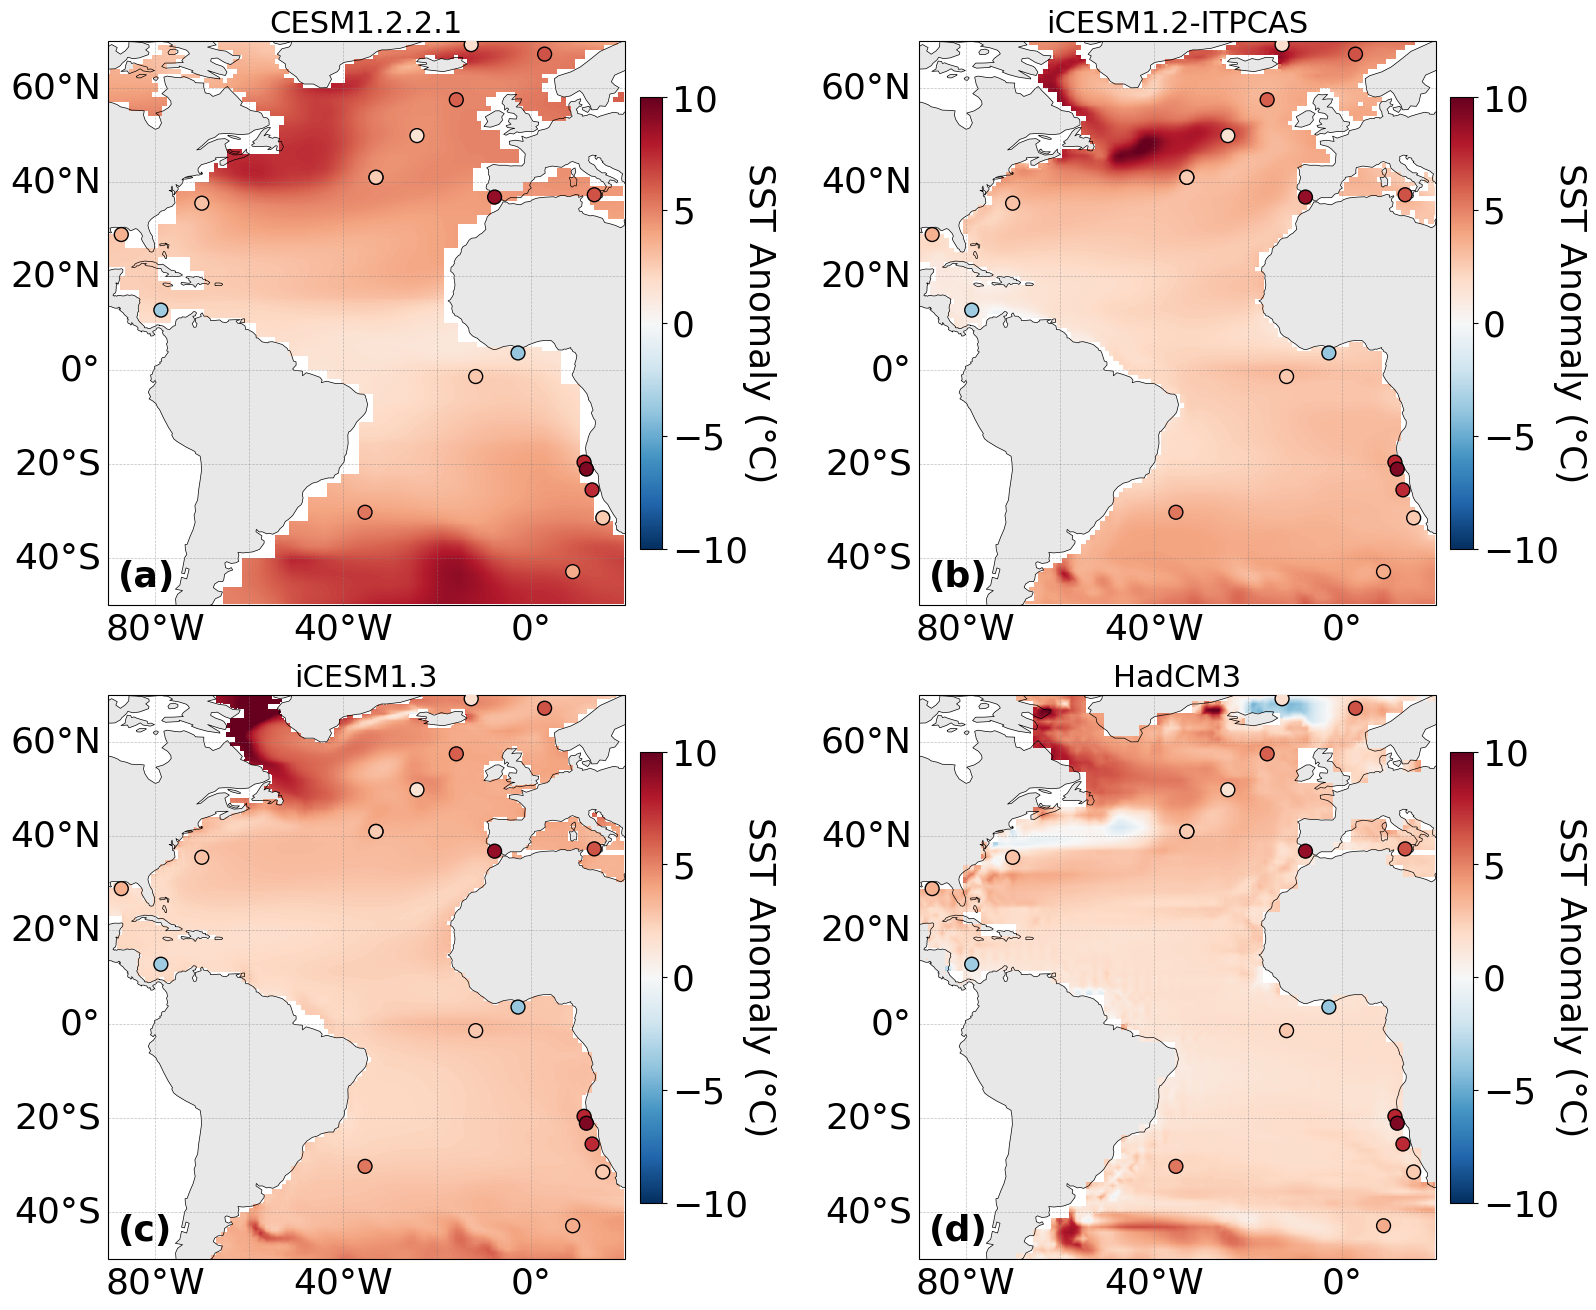

In [4]:
# Self-contained SST anomaly figure: recompute everything needed inside this cell

lat_target = np.linspace(-50, 70, 600)
lon_target = np.linspace(-90, 20, 600)
lon_target_mesh, lat_target_mesh = np.meshgrid(lon_target, lat_target)

# Model 1: iCESM1.2-ITPCAS
plio1 = regrid_to_target_fast(
    Plio_lat, Plio_lon, Plio_SST,
    lat_target_mesh, lon_target_mesh,
    mesh=(Plio_lat.ndim == 2),
    do_mask=False,
)
pre1 = regrid_to_target_fast(
    preind_temp_lat, preind_temp_lon, preind_SST,
    lat_target_mesh, lon_target_mesh,
    mesh=(preind_temp_lat.ndim == 2),
    do_mask=False,
)
SST_anomaly_1 = plio1 - pre1

# Model 2: HadCM3
plio2 = regrid_to_target_fast(
    hadcm3_Plio_lat, hadcm3_Plio_lon, hadcm3_Plio_SST,
    lat_target_mesh, lon_target_mesh,
    mesh=(hadcm3_Plio_lat.ndim == 2),
    do_mask=False,
)
pre2 = regrid_to_target_fast(
    hadcm3_Plio_lat, hadcm3_Plio_lon, hadcm3_preind_SST,
    lat_target_mesh, lon_target_mesh,
    mesh=(hadcm3_Plio_lat.ndim == 2),
    do_mask=False,
)
SST_anomaly_2 = plio2 - pre2

# Model 3: CESM1.2
plio3 = regrid_to_target_fast(
    icesm13_Plio_lat, icesm13_Plio_lon, icesm13_Plio_SST,
    lat_target_mesh, lon_target_mesh,
    mesh=(icesm13_Plio_lat.ndim == 2),
    do_mask=False,
)
pre3 = regrid_to_target_fast(
    icesm13_preind_lat, icesm13_preind_lon, icesm13_preind_SST,
    lat_target_mesh, lon_target_mesh,
    mesh=(icesm13_preind_lat.ndim == 2),
    do_mask=False,
)
SST_anomaly_3 = plio3 - pre3

# Model 4: CESM1.2.2.1
plio4 = regrid_to_target_fast(
    cesm122_Plio_lat, cesm122_Plio_lon, cesm122_Plio_SST,
    lat_target_mesh, lon_target_mesh,
    mesh=(cesm122_Plio_lat.ndim == 2),
    do_mask=False,
)
try:
    pre4 = regrid_to_target_fast(
        cesm122_preind_lat, cesm122_preind_lon, cesm122_preind_SST,
        lat_target_mesh, lon_target_mesh,
        mesh=(cesm122_preind_lat.ndim == 2),
        do_mask=False,
    )
except Exception as e:
    print(f"Model 4 fast regrid fallback due to: {e}")

    cesm122_preind_lat_fallback = np.asarray(cesm122_preind_lat)
    cesm122_preind_lon_fallback = np.asarray(cesm122_preind_lon)
    cesm122_preind_SST_fallback = np.ma.asarray(cesm122_preind_SST)

    # Use the surface layer if the preindustrial SST is 3D
    while cesm122_preind_SST_fallback.ndim > 2:
        cesm122_preind_SST_fallback = cesm122_preind_SST_fallback[0]

    # Align mesh and data orientation robustly
    def _align_mesh_and_data(data, lat, lon):
        data = np.ma.asarray(data)
        lat_a = np.asarray(lat)
        lon_a = np.asarray(lon)

        # build default meshes (lon, lat)
        if lat_a.ndim == 1 and lon_a.ndim == 1:
            lon_mesh, lat_mesh = np.meshgrid(lon_a, lat_a)
        else:
            lon_mesh, lat_mesh = lon_a, lat_a

        # exact match
        if data.shape == lon_mesh.shape:
            return data, lat_mesh, lon_mesh, "ok"

        # try transposing data
        if data.T.shape == lon_mesh.shape:
            return data.T, lat_mesh, lon_mesh, "transposed-data"

        # try transposing meshes (coords were mesh-shaped but swapped)
        if lon_mesh.T.shape == data.shape and lat_mesh.T.shape == data.shape:
            return data, lat_mesh.T, lon_mesh.T, "transposed-mesh"

        # try swapping 1D lat/lon when building mesh (common inversion)
        if lat_a.ndim == 1 and lon_a.ndim == 1:
            lon_mesh_sw, lat_mesh_sw = np.meshgrid(lat_a, lon_a)  # swapped
            if data.shape == lon_mesh_sw.shape:
                return data, lat_mesh_sw, lon_mesh_sw, "swapped-mesh-1D"
            if data.T.shape == lon_mesh_sw.shape:
                return data.T, lat_mesh_sw, lon_mesh_sw, "transposed-data+swapped-mesh-1D"

        # try squeezing and transposing as a last resort
        d_squeezed = np.squeeze(data)
        if d_squeezed.shape == lon_mesh.shape:
            return d_squeezed, lat_mesh, lon_mesh, "squeezed"
        if d_squeezed.T.shape == lon_mesh.shape:
            return d_squeezed.T, lat_mesh, lon_mesh, "squeezed+transposed"

        # give up — return what we have and a diagnostic note
        return data, lat_mesh, lon_mesh, f"unmatched-shapes data{data.shape} mesh{lon_mesh.shape}"

    cesm122_preind_SST_fallback, cesm122_preind_lat_fallback, cesm122_preind_lon_fallback, _note = _align_mesh_and_data(
        cesm122_preind_SST_fallback, cesm122_preind_lat_fallback, cesm122_preind_lon_fallback
    )
    print("Model 4 fallback alignment:", _note)

    pre4 = regrid_to_target_fast(
        cesm122_preind_lat_fallback,
        cesm122_preind_lon_fallback,
        cesm122_preind_SST_fallback,
        lat_target_mesh,
        lon_target_mesh,
        mesh=True,
        do_mask=False,
    )
SST_anomaly_4 = plio4 - pre4

# Apply Atlantic mask
SST_anomaly_1_masked = apply_atlantic_mask_2d_sst(SST_anomaly_1, lat_target_mesh, lon_target_mesh)
SST_anomaly_2_masked = apply_atlantic_mask_2d_sst(SST_anomaly_2, lat_target_mesh, lon_target_mesh)
SST_anomaly_3_masked = apply_atlantic_mask_2d_sst(SST_anomaly_3, lat_target_mesh, lon_target_mesh)
SST_anomaly_4_masked = apply_atlantic_mask_2d_sst(SST_anomaly_4, lat_target_mesh, lon_target_mesh)

# Shared centered color scale
vals = []
for arr in (SST_anomaly_1_masked, SST_anomaly_2_masked, SST_anomaly_3_masked, SST_anomaly_4_masked):
    vals.append(np.nanpercentile(np.abs(np.asarray(arr, float)), 99))

vmax_common = float(np.nanmax(vals)) if len(vals) else 1.0
if not np.isfinite(vmax_common) or vmax_common == 0:
    vmax_common = 1.0

norm_common = TwoSlopeNorm(vcenter=0.0, vmin=-10.0, vmax=10.0)

# Atlantic-only observations
obs_points = np.array([sst_anomalies_bayesian['Longitude'], sst_anomalies_bayesian['Latitude']]).T
obs_atlantic_mask = atlantic_polygon.contains_points(obs_points)
sst_obs_atlantic = sst_anomalies_bayesian[obs_atlantic_mask].copy()

# Plot

plt.rcParams.update({
    "font.size": 26,
    "axes.labelsize": 26,
    "xtick.labelsize": 26,
    "ytick.labelsize": 26,
})

fig = plt.figure(figsize=(18, 14))
gs = GridSpec(2, 2, figure=fig, hspace=0.16, wspace=0.10, left=0.06, right=0.92, top=0.95, bottom=0.08)

ax1 = fig.add_subplot(gs[0, 1], projection=ccrs.PlateCarree())
plot_sst_anomaly_with_obs(
    SST_anomaly_1_masked, lat_target_mesh, lon_target_mesh,
    sst_obs_atlantic, 'iCESM1.2-ITPCAS',
    ax=ax1, norm=norm_common
)

ax2 = fig.add_subplot(gs[1, 1], projection=ccrs.PlateCarree())
plot_sst_anomaly_with_obs(
    SST_anomaly_2_masked, lat_target_mesh, lon_target_mesh,
    sst_obs_atlantic, 'HadCM3',
    ax=ax2, norm=norm_common
)

ax3 = fig.add_subplot(gs[1, 0], projection=ccrs.PlateCarree())
plot_sst_anomaly_with_obs(
    SST_anomaly_3_masked, lat_target_mesh, lon_target_mesh,
    sst_obs_atlantic, 'iCESM1.3',
    ax=ax3, norm=norm_common
)

ax4 = fig.add_subplot(gs[0, 0], projection=ccrs.PlateCarree())
plot_sst_anomaly_with_obs(
    SST_anomaly_4_masked, lat_target_mesh, lon_target_mesh,
    sst_obs_atlantic, 'CESM1.2.2.1',
    ax=ax4, norm=norm_common
)

for ax, label in zip([ax4, ax1, ax3, ax2], ["(a)", "(b)", "(c)", "(d)"]):
    ax.text(
        0.02, 0.02, label,
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=26, fontweight="bold",
        zorder=20,
    )

plt.tight_layout()
fig.savefig(FIG_DIR / "SST_anomaly.png", dpi=300, bbox_inches="tight")
plt.show()
